### **BUSINESS UNDERSTANDING**

#### SDG 7: Affordable and Clean Energy 
#BUSINESS-UNDERSTANDING #SDG7 #Kenya #EnergyAccess

#### Why SDG 7
- I chose SDG7 due to a couple of factors that affect the energy sectar eg. the power cuts , energy issues in hospitals and airports and many countries are still having low access to reliable energy even for consumption
- this project asks which countries lag behind and what is associated  with higher access

#### The problem
- Hundreds of millions of people still have no electricity. Without data on where the gaps are and what is linked to them,
governments and development partners cannot target investment. This project uses open data to show where access is lowest,
how it changed from 2000 to 2022, and which factors predict it.

#### Business objectives
1. Which countries lag on electricity access, and how has that changed since 2000?
2. Does a cleaner (more renewable) electricity mix go together with higher access?
3. What drives electricity access (income, urbanisation, energy mix)?

#### Success criteria
- Dashboard answers questions 1 and 2 clearly for a non-technical audience
- Regression predicts electricity access (% of population) with assumptions tested
  and reported with R² and MSE

#### Scope
Countries worldwide, 2000–2022, with a Kenya spotlight.

## **Data Understanding**




#### Data sources
| Source | Provides | Link |
|---|---|---|
| Our World in Data energy dataset | Electricity mix, per-capita energy, population | https://github.com/owid/energy-data |
| World Bank Open Data | Electricity access (EG.ELC.ACCS.ZS), renewable share of final energy (EG.FEC.RNEW.ZS), GDP per capita (NY.GDP.PCAP.CD), urban population % (SP.URB.TOTL.IN.ZS) | https://data.worldbank.org |

Both sources are public and are not from Kaggle. The two were merged on ISO country code and year.

**Size:** 5,040 country-year rows, 220 countries, 2000–2022, 19 variables before cleaning.
After cleaning: 4,338 rows (86%), 194 countries, 18 columns.

**Target variable:** `access_electricity_pct`, the percentage of a country's population with access to electricity.

In [102]:
# #SETUP
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
from pathlib import Path
from functools import reduce

RAW = Path("../data/raw")
PROC = Path("../data/processed")
RAW.mkdir(parents=True, exist_ok=True)
PROC.mkdir(parents=True, exist_ok=True)
print("Setup done")

Setup done


In [103]:
# #DATA-COLLECTION #SOURCE:OurWorldInData
url = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"

cols = ["country", "year", "iso_code", "population", "gdp",
        "primary_energy_consumption", "energy_per_capita", "electricity_generation",
        "per_capita_electricity", "renewables_share_elec", "fossil_share_elec",
        "solar_share_elec", "wind_share_elec", "hydro_share_elec", "carbon_intensity_elec"]

owid = pd.read_csv(url, usecols=cols)
owid.to_csv(RAW / "owid_energy_raw.csv", index=False)   # #WHY keep an untouched copy

# #WHY rows without an iso_code are regions like "Africa" or "World", not countries
owid = owid[owid["iso_code"].notna() & owid["year"].between(2000, 2022)]
print(owid.shape)
owid.head()

(5040, 15)


,country,year,iso_code,population,gdp,carbon_intensity_elec,electricity_generation,energy_per_capita,fossil_share_elec,hydro_share_elec,per_capita_electricity,primary_energy_consumption,renewables_share_elec,solar_share_elec,wind_share_elec
126,Afghanistan,2000,AFG,20130334.0,1.128379e+10,250.00,0.48,262.680,35.417,64.583,23.845,5.288,64.583,0.0,0.0
127,Afghanistan,2001,AFG,20284303.0,1.102127e+10,217.39,0.69,179.892,27.536,72.464,34.016,3.649,72.464,0.0,0.0
128,Afghanistan,2002,AFG,21378123.0,1.880487e+10,169.01,0.71,155.695,21.127,78.873,33.212,3.328,78.873,0.0,0.0
129,Afghanistan,2003,AFG,22733053.0,2.107434e+10,241.76,0.91,174.558,30.769,69.231,40.030,3.968,69.231,0.0,0.0
130,Afghanistan,2004,AFG,23560656.0,2.233257e+10,227.85,0.79,157.758,29.114,70.886,33.530,3.717,70.886,0.0,0.0


In [104]:
# #DATA-COLLECTION #SOURCE:WorldBankAPI #RETRY #CACHE
import time

indicators = {
    "EG.ELC.ACCS.ZS":    "access_electricity_pct",      # SDG 7.1.1
    "EG.FEC.RNEW.ZS":    "renewable_final_energy_pct",  # SDG 7.2.1
    "NY.GDP.PCAP.CD":    "gdp_per_capita_usd",
    "SP.URB.TOTL.IN.ZS": "urban_pop_pct",
}

def fetch_wb(code, name, retries=4):
    # #WHY if we already downloaded this indicator, reuse the saved file
    cache = RAW / f"wb_{code}.csv"
    if cache.exists():
        print(f"{name}: loaded from saved file")
        return pd.read_csv(cache)

    url = f"https://api.worldbank.org/v2/country/all/indicator/{code}"
    rows, page = [], 1

    while True:
        # #WHY small pages (1000 rows) are less likely to time out than one huge request
        params = {"format": "json", "per_page": 1000, "page": page, "date": "2000:2022"}

        for attempt in range(1, retries + 1):
            try:
                r = requests.get(url, params=params, timeout=(10, 120))
                r.raise_for_status()
                payload = r.json()
                if len(payload) < 2 or payload[1] is None:
                    raise ValueError(f"Empty response: {payload}")
                break
            except (requests.exceptions.RequestException, ValueError) as e:
                wait = 5 * attempt
                print(f"  {name} page {page}, attempt {attempt} failed ({type(e).__name__}). Retrying in {wait}s...")
                if attempt == retries:
                    raise
                time.sleep(wait)

        rows.extend(payload[1])
        print(f"  {name}: page {page} of {payload[0]['pages']} done")
        if page >= payload[0]["pages"]:
            break
        page += 1

    out = pd.DataFrame({
        "iso_code": [x["countryiso3code"] for x in rows],
        "year": [int(x["date"]) for x in rows],
        name: [x["value"] for x in rows],
    })
    out.to_csv(cache, index=False)
    return out

frames = [fetch_wb(code, name) for code, name in indicators.items()]
wb = reduce(lambda a, b: a.merge(b, on=["iso_code", "year"], how="outer"), frames)
wb = wb[wb["iso_code"] != ""]
wb.to_csv(RAW / "worldbank_sdg7_raw.csv", index=False)
print(wb.shape)
wb.head()

access_electricity_pct: loaded from saved file
renewable_final_energy_pct: loaded from saved file
gdp_per_capita_usd: loaded from saved file
urban_pop_pct: loaded from saved file
(20378, 6)


,iso_code,year,access_electricity_pct,renewable_final_energy_pct,gdp_per_capita_usd,urban_pop_pct
0,ABW,2000,91.7,0.2,20681.023027,65.354550
1,ABW,2001,100.0,0.2,20740.132583,65.335114
2,ABW,2002,100.0,0.2,21307.248251,65.282069
3,ABW,2003,100.0,0.2,21949.485996,65.198292
4,ABW,2004,100.0,0.2,23700.631990,65.088653


### Merge into one raw table

In [105]:
# #DATA-INTEGRATION
# #WHY left join: OWID is the country-and-year backbone, World Bank columns attach to it
df_raw = owid.merge(wb, on=["iso_code", "year"], how="left")
df_raw.to_csv(PROC / "sdg7_merged_raw.csv", index=False)
print(df_raw.shape)
df_raw.head()

(5040, 19)


,country,year,iso_code,population,gdp,carbon_intensity_elec,electricity_generation,energy_per_capita,fossil_share_elec,hydro_share_elec,per_capita_electricity,primary_energy_consumption,renewables_share_elec,solar_share_elec,wind_share_elec,access_electricity_pct,renewable_final_energy_pct,gdp_per_capita_usd,urban_pop_pct
0,Afghanistan,2000,AFG,20130334.0,1.128379e+10,250.00,0.48,262.680,35.417,64.583,23.845,5.288,64.583,0.0,0.0,4.4,45.0,174.930991,18.558200
1,Afghanistan,2001,AFG,20284303.0,1.102127e+10,217.39,0.69,179.892,27.536,72.464,34.016,3.649,72.464,0.0,0.0,9.3,45.6,138.706822,18.741238
2,Afghanistan,2002,AFG,21378123.0,1.880487e+10,169.01,0.71,155.695,21.127,78.873,33.212,3.328,78.873,0.0,0.0,14.1,37.8,178.954088,18.941248
3,Afghanistan,2003,AFG,22733053.0,2.107434e+10,241.76,0.91,174.558,30.769,69.231,40.030,3.968,69.231,0.0,0.0,19.0,36.7,198.871116,19.160035
4,Afghanistan,2004,AFG,23560656.0,2.233257e+10,227.85,0.79,157.758,29.114,70.886,33.530,3.717,70.886,0.0,0.0,23.8,44.2,221.763654,19.399359


### Dissect: what is in the table

In [106]:
# #DATA-UNDERSTANDING #STRUCTURE
print("Rows, columns:", df_raw.shape)
print("Countries:", df_raw["iso_code"].nunique())
print("Years:", df_raw["year"].min(), "to", df_raw["year"].max())
print()
df_raw.info()

Rows, columns: (5040, 19)
Countries: 220
Years: 2000 to 2022

<class 'pandas.DataFrame'>
RangeIndex: 5040 entries, 0 to 5039
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   country                     5040 non-null   str    
 1   year                        5040 non-null   int64  
 2   iso_code                    5040 non-null   str    
 3   population                  5005 non-null   float64
 4   gdp                         3790 non-null   float64
 5   carbon_intensity_elec       4866 non-null   float64
 6   electricity_generation      4889 non-null   float64
 7   energy_per_capita           4952 non-null   float64
 8   fossil_share_elec           4866 non-null   float64
 9   hydro_share_elec            4778 non-null   float64
 10  per_capita_electricity      4889 non-null   float64
 11  primary_energy_consumption  4987 non-null   float64
 12  renewables_share_elec       4866 non-nu

### Dissect: how mich is missing?

gdp                           24.8
renewable_final_energy_pct     9.2
gdp_per_capita_usd             8.5
wind_share_elec                7.4
access_electricity_pct         7.2
urban_pop_pct                  6.4
hydro_share_elec               5.2
solar_share_elec               3.8
carbon_intensity_elec          3.5
renewables_share_elec          3.5
fossil_share_elec              3.5
electricity_generation         3.0
per_capita_electricity         3.0
energy_per_capita              1.7
primary_energy_consumption     1.1
population                     0.7
iso_code                       0.0
country                        0.0
year                           0.0
dtype: float64


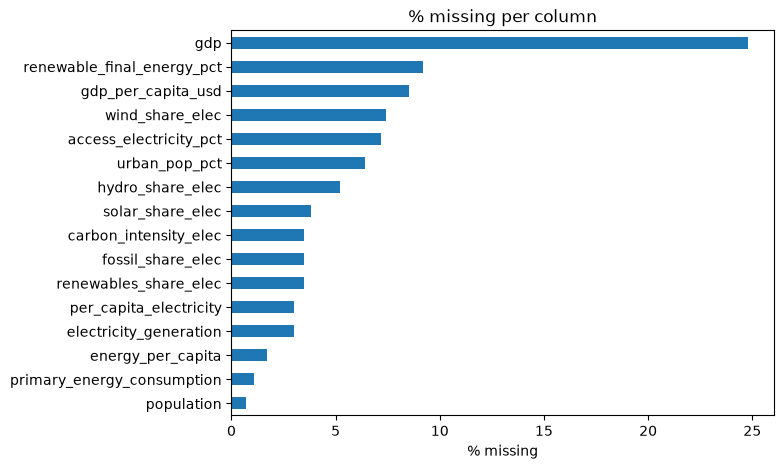

In [107]:
# #DATA-UNDERSTANDING #MISSING-VALUES
missing = (df_raw.isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing)

missing[missing > 0].sort_values().plot(kind="barh", figsize=(7, 5), title="% missing per column")
plt.xlabel("% missing")
plt.show()

 
 The chart shows which columns have gaps and which are close to empty. This decides the cleaning rules in Phase 3, so keep it open.

#### **Dissect: duplicates**

In [108]:
# #DATA-UNDERSTANDING #DUPLICATES
# #WHY each country should appear once per year, so more than 0 means a problem
print("Duplicate country-year rows:", df_raw.duplicated(subset=["iso_code", "year"]).sum())

Duplicate country-year rows: 0


#### dissect impossible values

In [109]:
# #DATA-UNDERSTANDING #VALIDITY
# #WHY percentages must sit between 0 and 100
pct_cols = ["access_electricity_pct", "renewable_final_energy_pct", "urban_pop_pct",
            "renewables_share_elec", "fossil_share_elec", "solar_share_elec",
            "wind_share_elec", "hydro_share_elec"]

for c in pct_cols:
    bad = ((df_raw[c] < 0) | (df_raw[c] > 100)).sum()
    print(f"{c}: {bad} impossible values")

# #WHY these can never be negative
nonneg = ["population", "gdp_per_capita_usd", "per_capita_electricity", "energy_per_capita"]
print()
print((df_raw[nonneg] < 0).sum())

access_electricity_pct: 0 impossible values
renewable_final_energy_pct: 0 impossible values
urban_pop_pct: 0 impossible values
renewables_share_elec: 0 impossible values
fossil_share_elec: 0 impossible values
solar_share_elec: 0 impossible values
wind_share_elec: 0 impossible values
hydro_share_elec: 0 impossible values

population                0
gdp_per_capita_usd        0
per_capita_electricity    0
energy_per_capita         0
dtype: int64


#### Descriptive stats

In [110]:
# #DATA-UNDERSTANDING #DESCRIPTIVE-STATS
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
year,5040.0,2.011030e+03,6.630000e+00,2.000000e+03,2.005000e+03,2.011000e+03,2.017000e+03,2.022000e+03
population,5005.0,3.264637e+07,1.299453e+08,1.776000e+03,7.093870e+05,5.728196e+06,2.137812e+07,1.426437e+09
gdp,3790.0,5.697030e+11,1.921936e+12,3.128536e+08,2.366483e+10,7.727651e+10,3.515815e+11,2.696602e+13
carbon_intensity_elec,4866.0,4.775900e+02,2.482600e+02,0.000000e+00,2.859100e+02,5.332900e+02,6.538500e+02,1.306720e+03
electricity_generation,4889.0,1.025700e+02,4.742100e+02,0.000000e+00,6.800000e-01,6.970000e+00,4.357000e+01,8.848710e+03
energy_per_capita,4952.0,2.697166e+04,4.298277e+04,0.000000e+00,3.077780e+03,1.291344e+04,3.509806e+04,6.518366e+05
fossil_share_elec,4866.0,6.568000e+01,3.372000e+01,0.000000e+00,3.941000e+01,7.524000e+01,9.836000e+01,1.000000e+02
hydro_share_elec,4778.0,2.595000e+01,3.157000e+01,0.000000e+00,0.000000e+00,1.021000e+01,4.716000e+01,1.000000e+02
per_capita_electricity,4889.0,3.794880e+03,5.197700e+03,0.000000e+00,4.947200e+02,2.130830e+03,5.236300e+03,5.604873e+04
primary_energy_consumption,4987.0,6.517400e+02,2.881120e+03,0.000000e+00,5.010000e+00,3.876000e+01,2.947900e+02,4.451649e+04


#### Look at the target: electricity access

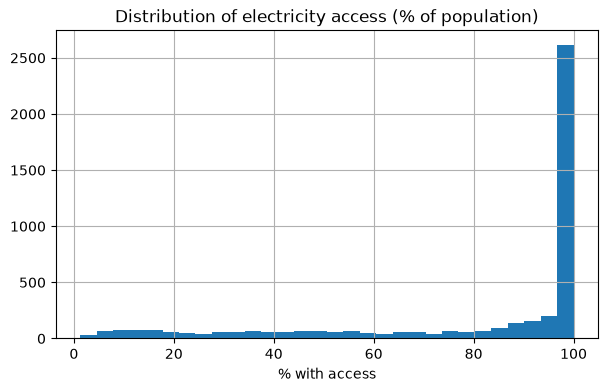

count    4677.0
mean       80.5
std        29.3
min         1.3
25%        66.1
50%        98.8
75%       100.0
max       100.0
Name: access_electricity_pct, dtype: float64


In [111]:
# #DATA-UNDERSTANDING #TARGET:access_electricity_pct
df_raw["access_electricity_pct"].hist(bins=30, figsize=(7, 4))
plt.title("Distribution of electricity access (% of population)")
plt.xlabel("% with access")
plt.show()

print(df_raw["access_electricity_pct"].describe().round(1))

# this shape matters later when we test the regression assumptions


#### Answer the business questions so far

In [112]:
# #DATA-UNDERSTANDING #SDG7.1.1
latest = df_raw[df_raw["year"] == 2022]
print("10 lowest-access countries, 2022")
print(latest.nsmallest(10, "access_electricity_pct")[["country", "access_electricity_pct"]])

print("\nKenya, last 10 years")
df_raw[df_raw["country"] == "Kenya"][["year", "access_electricity_pct", "renewables_share_elec"]].tail(10)

10 lowest-access countries, 2022
                           country  access_electricity_pct
4257                   South Sudan                     8.4
735                        Burundi                    10.3
896                           Chad                    11.7
2733                        Malawi                    14.0
873       Central African Republic                    15.7
3556              Papua New Guinea                    19.0
712                   Burkina Faso                    19.5
3303                         Niger                    19.5
1218  Democratic Republic of Congo                    21.5
4085                  Sierra Leone                    29.4

Kenya, last 10 years


,year,access_electricity_pct,renewables_share_elec
2402,2013,40.1,78.342
2403,2014,36.0,76.413
2404,2015,41.6,89.806
2405,2016,53.1,89.256
2406,2017,55.8,80.886
2407,2018,61.2,86.283
2408,2019,69.7,88.668
2409,2020,71.5,93.579
2410,2021,76.5,89.822
2411,2022,76.0,87.809


### **Data Preparation (cleaning)**

In [113]:
# working on a copy 

# DATA-PREPARATION #STEP1
# WHY df_raw stays untouched so we can always compare before and after
df = df_raw.copy()
df = df.sort_values(["iso_code", "year"]).reset_index(drop=True)
print("Starting rows:", len(df))


Starting rows: 5040


In [114]:
# Drop rows where the target is missing

# DATA-PREPARATION #STEP2 #TARGET
# WHY we cannot learn from or chart a country-year with no access figure,
#      and we should never invent the thing we are trying to explain
before = len(df)
df = df.dropna(subset=["access_electricity_pct"])
print(f"Dropped {before - len(df)} rows. Remaining: {len(df)}")


Dropped 363 rows. Remaining: 4677


In [115]:
# Drop columns that are redundant or mostly empty

# DATA-PREPARATION #STEP3 #COLUMNS
# Rule 1: more than 40% missing means too little left to trust
too_sparse = missing[missing > 40].index.tolist()

# Rule 2: total columns just reflect country size. We keep per-capita versions
#         and the World Bank GDP per capita instead.
redundant = ["gdp", "primary_energy_consumption", "electricity_generation"]

to_drop = [c for c in (too_sparse + redundant) if c in df.columns]
df = df.drop(columns=to_drop)
print("Dropped columns:", to_drop)
print("Columns left:", df.shape[1])

Dropped columns: ['gdp', 'primary_energy_consumption', 'electricity_generation']
Columns left: 16


In [116]:
# fill the gaps in the predictors

# DATA-PREPARATION #STEP4 #IMPUTATION
# WHY fill within each country over time (a gap in 2011 is best guessed from
#      Kenya's 2010 and 2012), not with one global average that ignores the country.
# WHY limit=3 stops us from guessing across long stretches of nothing.
# WHY we do not touch the target column.
fill_cols = [c for c in df.select_dtypes("number").columns
             if c not in ["year", "access_electricity_pct"]]

print("Missing BEFORE:")
print(df[fill_cols].isna().sum())

df[fill_cols] = df.groupby("iso_code")[fill_cols].transform(
    lambda s: s.interpolate(limit=3, limit_direction="both")
)

print("\nMissing AFTER:")
print(df[fill_cols].isna().sum())

Missing BEFORE:
population                      0
carbon_intensity_elec          92
energy_per_capita              53
fossil_share_elec              92
hydro_share_elec              161
per_capita_electricity         92
renewables_share_elec          92
solar_share_elec               95
wind_share_elec               260
renewable_final_energy_pct    141
gdp_per_capita_usd             97
urban_pop_pct                   0
dtype: int64

Missing AFTER:
population                      0
carbon_intensity_elec          92
energy_per_capita              49
fossil_share_elec              92
hydro_share_elec              161
per_capita_electricity         92
renewables_share_elec          92
solar_share_elec               92
wind_share_elec               217
renewable_final_energy_pct      0
gdp_per_capita_usd             76
urban_pop_pct                   0
dtype: int64


In [117]:
# Dropping rows that are still incomplete

# DATA-PREPARATION #STEP5 #ROWS
# WHY the gaps left are too long to fill honestly, and regression cannot take blanks
before = len(df)
df = df.dropna(subset=fill_cols)
print(f"Dropped {before - len(df)} rows. Remaining: {len(df)}")
print("Countries still in the data:", df["iso_code"].nunique())

Dropped 339 rows. Remaining: 4338
Countries still in the data: 194


solar_share_elec              874
wind_share_elec               871
population                    493
gdp_per_capita_usd            390
energy_per_capita             243
per_capita_electricity        213
carbon_intensity_elec          23
fossil_share_elec               0
renewables_share_elec           0
hydro_share_elec                0
renewable_final_energy_pct      0
urban_pop_pct                   0
dtype: int64


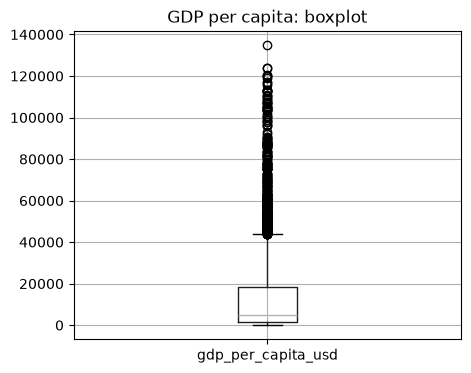

In [118]:
# checking for outliers (looking and not deleting)

 #DATA-PREPARATION #STEP6 #OUTLIERS
Q1 = df[fill_cols].quantile(0.25)
Q3 = df[fill_cols].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[fill_cols] < (Q1 - 1.5 * IQR)) | (df[fill_cols] > (Q3 + 1.5 * IQR))).sum()
print(outliers.sort_values(ascending=False))

df.boxplot(column="gdp_per_capita_usd", figsize=(5, 4))
plt.title("GDP per capita: boxplot")
plt.show()

In [119]:
# create new useful columns

# DATA-PREPARATION #STEP7 #FEATURE-ENGINEERING
# WHY GDP is heavily skewed, and log makes it behave better in a linear model
df["gdp_per_capita_log"] = np.log(df["gdp_per_capita_usd"])

# WHY the "gap" is easier to talk about in a dashboard: how many people are left without power
df["electricity_gap_pct"] = 100 - df["access_electricity_pct"]

df[["country", "year", "gdp_per_capita_usd", "gdp_per_capita_log", "electricity_gap_pct"]].head()

,country,year,gdp_per_capita_usd,gdp_per_capita_log,electricity_gap_pct
0,Aruba,2000,20681.023027,9.936972,8.3
1,Aruba,2001,20740.132583,9.939826,0.0
2,Aruba,2002,21307.248251,9.966803,0.0
3,Aruba,2003,21949.485996,9.996499,0.0
4,Aruba,2004,23700.631990,10.073257,0.0


In [120]:
# Final health check

# DATA-PREPARATION #STEP8 #VALIDATION
print("Shape:", df.shape)
print("Missing values left:", df.isna().sum().sum())
print("Duplicates:", df.duplicated(subset=["iso_code", "year"]).sum())
print("Kenya rows kept:", (df["country"] == "Kenya").sum())
print(f"Rows kept: {len(df)} of {len(df_raw)} ({len(df)/len(df_raw):.0%})")
df.describe().T.round(2)


Shape: (4338, 18)
Missing values left: 0
Duplicates: 0
Kenya rows kept: 23
Rows kept: 4338 of 5040 (86%)


,count,mean,std,min,25%,50%,75%,max
year,4338.0,2011.14,6.600000e+00,2000.00,2005.00,2011.00,2017.00,2.022000e+03
population,4338.0,37015029.19,1.390318e+08,10032.00,1395492.75,7205717.50,25234220.75,1.426437e+09
carbon_intensity_elec,4338.0,459.63,2.484800e+02,0.00,257.02,505.36,649.15,1.306720e+03
energy_per_capita,4338.0,25672.52,4.100049e+04,101.88,3044.52,12180.62,33996.09,6.518366e+05
fossil_share_elec,4338.0,63.61,3.420000e+01,0.00,36.47,71.97,96.57,1.000000e+02
hydro_share_elec,4338.0,27.18,3.217000e+01,0.00,0.04,11.34,49.13,1.000000e+02
per_capita_electricity,4338.0,3716.34,5.356930e+03,4.81,450.10,1922.86,5125.78,5.604873e+04
renewables_share_elec,4338.0,32.46,3.332000e+01,0.00,2.69,19.46,57.52,1.000000e+02
solar_share_elec,4338.0,0.86,2.600000e+00,0.00,0.00,0.00,0.24,3.788000e+01
wind_share_elec,4338.0,1.68,4.890000e+00,0.00,0.00,0.00,0.56,5.714000e+01


In [121]:
# DATA-PREPARATION #STEP9 #EXPORT

df.to_csv(PROC / "sdg7_clean.csv", index=False)

print("Saved to", PROC / "sdg7_clean.csv")

# This cell saves your prepared dataset for use in Power BI and subsequent analysis.

Saved to ..\data\processed\sdg7_clean.csv


## **Modelling**

- The objective of this phase is to develop a linear regression model that predicts national electricity access using relevant economic, demographic, and energy-related indicators.

- The target variable is electricity access, measured as the percentage of a country's population with access to electricity. The model will use information from the prepared dataset to investigate relationships between electricity access and potential explanatory variables.

- The modeling process will include data splitting, baseline model development, regression diagnostics, and evaluation using R² and Mean Squared Error (MSE).

- This analysis supports Sustainable Development Goal 7, which aims to ensure access to affordable, reliable, sustainable, and modern energy for all.


In [122]:
# CRISP-DM PHASE 4: MODELING
# STEP 1: IMPORT MODELING LIBRARIES

# #IMPORTS #LINEAR-REGRESSION #MODEL-EVALUATION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("Modeling libraries imported successfully.")

Modeling libraries imported successfully.


In [123]:
# Before fitting a model, we need to confirm that the dataset contains the variables we expect.
# A regression model requires a clearly defined target variable and usable predictor variables.
# #DATA-VALIDATION #MODEL-PREPARATION

# Display the dimensions of the cleaned dataset
print("Dataset shape:", df.shape)

# Display the column names
print("\nAvailable columns:")
print(df.columns.tolist())

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Display the first five observations
print("\nFirst five observations:")
display(df.head())

Dataset shape: (4338, 18)

Available columns:
['country', 'year', 'iso_code', 'population', 'carbon_intensity_elec', 'energy_per_capita', 'fossil_share_elec', 'hydro_share_elec', 'per_capita_electricity', 'renewables_share_elec', 'solar_share_elec', 'wind_share_elec', 'access_electricity_pct', 'renewable_final_energy_pct', 'gdp_per_capita_usd', 'urban_pop_pct', 'gdp_per_capita_log', 'electricity_gap_pct']

Missing values per column:
country                       0
year                          0
iso_code                      0
population                    0
carbon_intensity_elec         0
energy_per_capita             0
fossil_share_elec             0
hydro_share_elec              0
per_capita_electricity        0
renewables_share_elec         0
solar_share_elec              0
wind_share_elec               0
access_electricity_pct        0
renewable_final_energy_pct    0
gdp_per_capita_usd            0
urban_pop_pct                 0
gdp_per_capita_log            0
electricity_gap_pct

,country,year,iso_code,population,carbon_intensity_elec,energy_per_capita,fossil_share_elec,hydro_share_elec,per_capita_electricity,renewables_share_elec,solar_share_elec,wind_share_elec,access_electricity_pct,renewable_final_energy_pct,gdp_per_capita_usd,urban_pop_pct,gdp_per_capita_log,electricity_gap_pct
0,Aruba,2000,ABW,88772.0,653.85,49760.848,100.0,0.0,8786.554,0.0,0.0,0.0,91.7,0.2,20681.023027,65.354550,9.936972,8.3
1,Aruba,2001,ABW,90320.0,654.32,50605.742,100.0,0.0,8968.113,0.0,0.0,0.0,100.0,0.2,20740.132583,65.335114,9.939826,0.0
2,Aruba,2002,ABW,91393.0,658.54,51697.395,100.0,0.0,8972.240,0.0,0.0,0.0,100.0,0.2,21307.248251,65.282069,9.966803,0.0
3,Aruba,2003,ABW,92324.0,654.76,56989.500,100.0,0.0,9098.393,0.0,0.0,0.0,100.0,0.2,21949.485996,65.198292,9.996499,0.0
4,Aruba,2004,ABW,93223.0,655.17,58857.523,100.0,0.0,9332.461,0.0,0.0,0.0,100.0,0.2,23700.631990,65.088653,10.073257,0.0


#### **Identify the target variable and predictors**

- Before training a model, we need to decide what we want it to predict.
- Can we predict a country's electricity access rate using selected economic, demographic, and energy-related indicators?
- Our target variable will be the percentage of the population with access to electricity. The other variables will be the predictors.

In [124]:

# Inspect the dataset to identify suitable regression variables.

# Display all column names
print("Available columns:")
for column in df.columns:
    print("-", column)

# Display the data types of each column
print("\nColumn data types:")
print(df.dtypes)

# Display descriptive statistics for numerical variables
print("\nDescriptive statistics:")
display(df.describe().T)

Available columns:
- country
- year
- iso_code
- population
- carbon_intensity_elec
- energy_per_capita
- fossil_share_elec
- hydro_share_elec
- per_capita_electricity
- renewables_share_elec
- solar_share_elec
- wind_share_elec
- access_electricity_pct
- renewable_final_energy_pct
- gdp_per_capita_usd
- urban_pop_pct
- gdp_per_capita_log
- electricity_gap_pct

Column data types:
country                           str
year                            int64
iso_code                          str
population                    float64
carbon_intensity_elec         float64
energy_per_capita             float64
fossil_share_elec             float64
hydro_share_elec              float64
per_capita_electricity        float64
renewables_share_elec         float64
solar_share_elec              float64
wind_share_elec               float64
access_electricity_pct        float64
renewable_final_energy_pct    float64
gdp_per_capita_usd            float64
urban_pop_pct                 float64
gdp_per_c

,count,mean,std,min,25%,50%,75%,max
year,4338.0,2.011136e+03,6.604541e+00,2000.000000,2.005000e+03,2.011000e+03,2.017000e+03,2.022000e+03
population,4338.0,3.701503e+07,1.390318e+08,10032.000000,1.395493e+06,7.205718e+06,2.523422e+07,1.426437e+09
carbon_intensity_elec,4338.0,4.596266e+02,2.484811e+02,0.000000,2.570200e+02,5.053600e+02,6.491500e+02,1.306720e+03
energy_per_capita,4338.0,2.567252e+04,4.100049e+04,101.881000,3.044520e+03,1.218062e+04,3.399609e+04,6.518366e+05
fossil_share_elec,4338.0,6.360949e+01,3.419959e+01,0.000000,3.646650e+01,7.196650e+01,9.656925e+01,1.000000e+02
hydro_share_elec,4338.0,2.718158e+01,3.217037e+01,0.000000,4.400000e-02,1.134050e+01,4.912525e+01,1.000000e+02
per_capita_electricity,4338.0,3.716345e+03,5.356927e+03,4.809000,4.501028e+02,1.922861e+03,5.125779e+03,5.604873e+04
renewables_share_elec,4338.0,3.246117e+01,3.332175e+01,0.000000,2.694750e+00,1.946150e+01,5.752100e+01,1.000000e+02
solar_share_elec,4338.0,8.625991e-01,2.602882e+00,0.000000,0.000000e+00,0.000000e+00,2.357500e-01,3.787900e+01
wind_share_elec,4338.0,1.679305e+00,4.887143e+00,0.000000,0.000000e+00,0.000000e+00,5.620000e-01,5.713800e+01


In [125]:
# Examine correlations between the variable
 #EXPLORATORY_DATA_ANALYSIS #CORRELATION

# Select numerical columns
numerical_df = df.select_dtypes(include=np.number)

# Calculate correlations between numerical variables
correlation_matrix = numerical_df.corr()

# Display the correlation matrix
display(correlation_matrix.round(2))


,year,population,carbon_intensity_elec,energy_per_capita,fossil_share_elec,hydro_share_elec,per_capita_electricity,renewables_share_elec,solar_share_elec,wind_share_elec,access_electricity_pct,renewable_final_energy_pct,gdp_per_capita_usd,urban_pop_pct,gdp_per_capita_log,electricity_gap_pct
year,1.00,0.02,-0.03,-0.02,-0.04,-0.04,0.04,0.05,0.40,0.28,0.15,-0.03,0.14,0.09,0.22,-0.15
population,0.02,1.00,0.10,-0.04,0.03,-0.04,-0.03,-0.04,0.00,0.02,0.05,-0.01,-0.06,-0.06,-0.06,-0.05
carbon_intensity_elec,-0.03,0.10,1.00,0.12,0.93,-0.83,-0.06,-0.87,-0.06,-0.12,0.19,-0.49,-0.04,0.12,0.11,-0.19
energy_per_capita,-0.02,-0.04,0.12,1.00,0.12,-0.19,0.69,-0.17,-0.02,0.06,0.38,-0.37,0.56,0.49,0.58,-0.38
fossil_share_elec,-0.04,0.03,0.93,0.12,1.00,-0.88,-0.08,-0.94,-0.05,-0.12,0.17,-0.48,0.00,0.13,0.13,-0.17
hydro_share_elec,-0.04,-0.04,-0.83,-0.19,-0.88,1.00,-0.03,0.95,-0.10,-0.11,-0.31,0.57,-0.17,-0.26,-0.32,0.31
per_capita_electricity,0.04,-0.03,-0.06,0.69,-0.08,-0.03,1.00,0.00,-0.03,0.08,0.42,-0.26,0.64,0.53,0.64,-0.42
renewables_share_elec,0.05,-0.04,-0.87,-0.17,-0.94,0.95,0.00,1.00,0.04,0.11,-0.25,0.56,-0.08,-0.21,-0.23,0.25
solar_share_elec,0.40,0.00,-0.06,-0.02,-0.05,-0.10,-0.03,0.04,1.00,0.26,0.10,-0.08,0.11,0.07,0.12,-0.10
wind_share_elec,0.28,0.02,-0.12,0.06,-0.12,-0.11,0.08,0.11,0.26,1.00,0.19,-0.08,0.32,0.19,0.30,-0.19


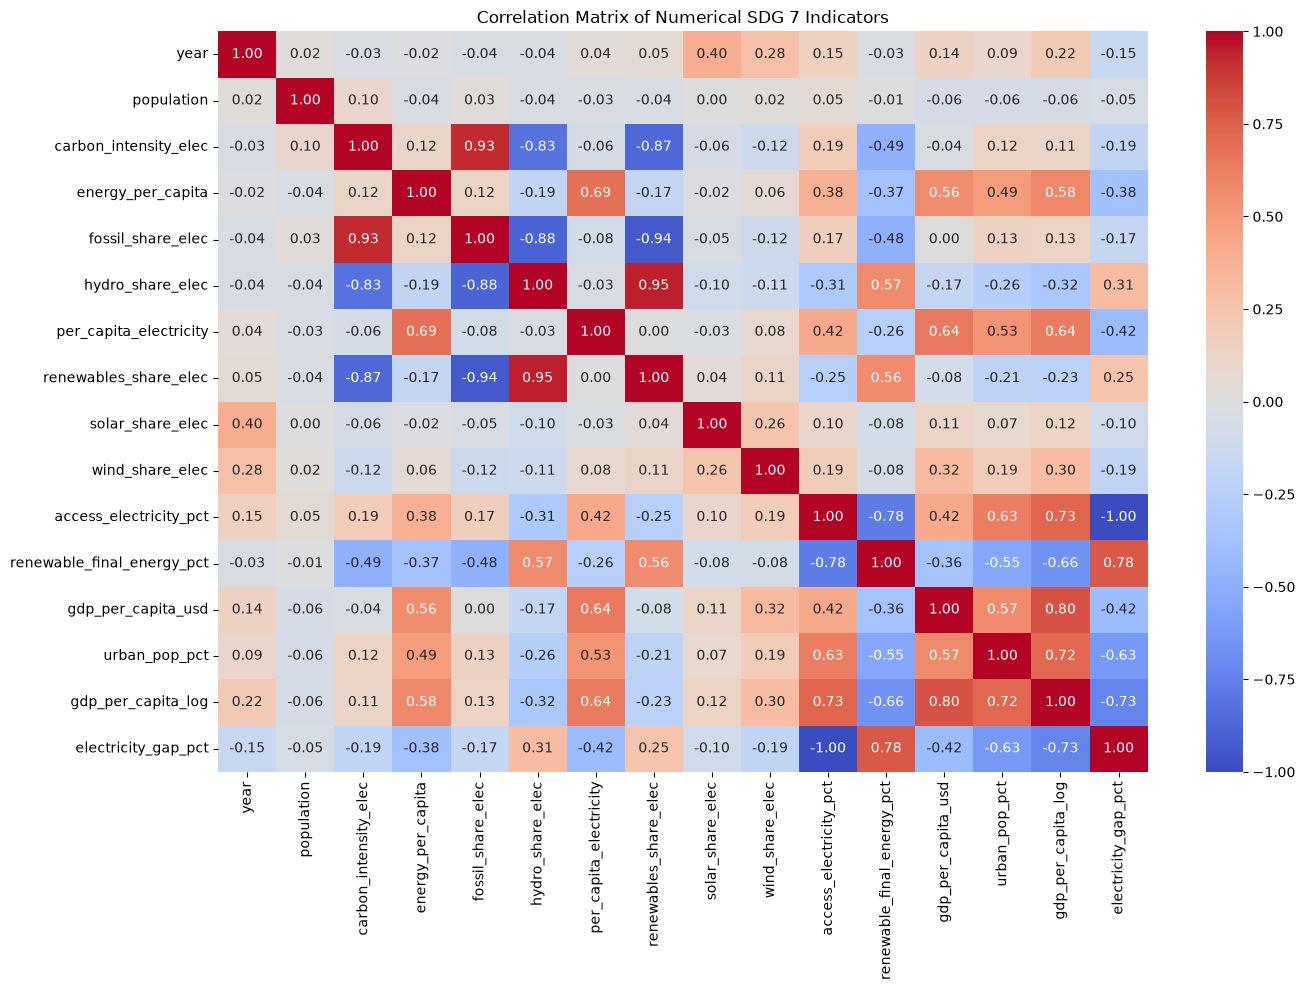

In [126]:
# Visualize the correlations

# CORRELATION_HEATMAP

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical SDG 7 Indicators")
plt.tight_layout()
plt.show()


#A correlation heatmap gives us a visual summary of relationships among the numerical indicators.


#### **Investigate the electricity-access gap**
- Before we build our regression model, let's establish whether electricity gap pct is mathematically derived from the target variable.

In [127]:
 #DATA_VALIDATION #TARGET_LEAKAGE

# Calculate the electricity-access gap directly from the target
calculated_gap = 100 - df["access_electricity_pct"]

# Compare the calculated gap with the existing gap column
gap_difference = (
    df["electricity_gap_pct"] - calculated_gap
).abs()

print("Mean absolute difference:", gap_difference.mean())
print("Maximum absolute difference:", gap_difference.max())

# Check whether the two definitions match within a small tolerance
if np.allclose(
    df["electricity_gap_pct"],
    calculated_gap,
    equal_nan=True
):
    print("The electricity gap is mathematically derived from electricity access.")
else:
    print("The electricity gap differs from 100 minus electricity access.")

Mean absolute difference: 0.0
Maximum absolute difference: 0.0
The electricity gap is mathematically derived from electricity access.


### **Visualize the relationship between electricity access and its potential predictors**

- let's examine how electricity access varies with selected economic, demographic, and energy indicators.



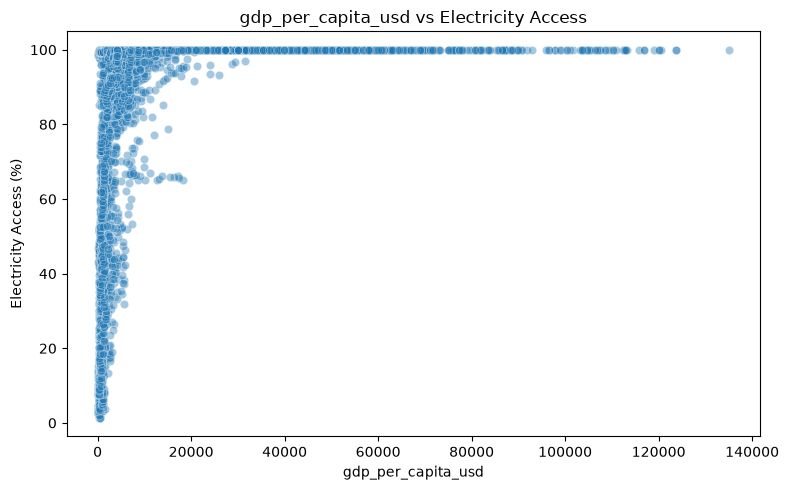

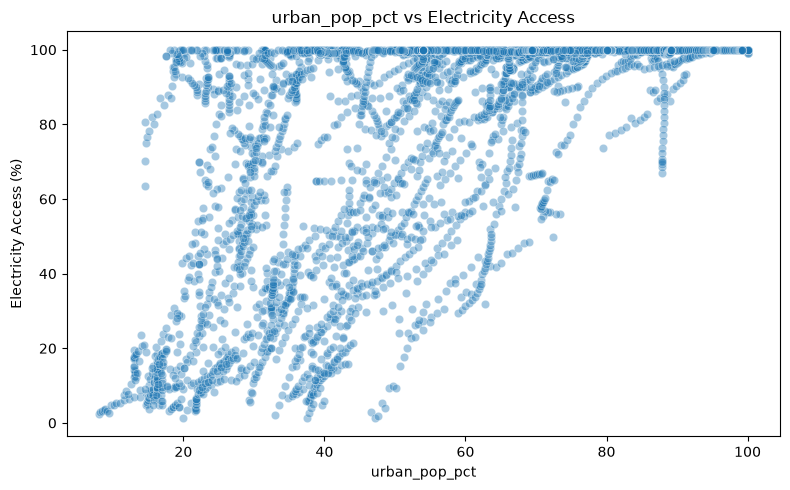

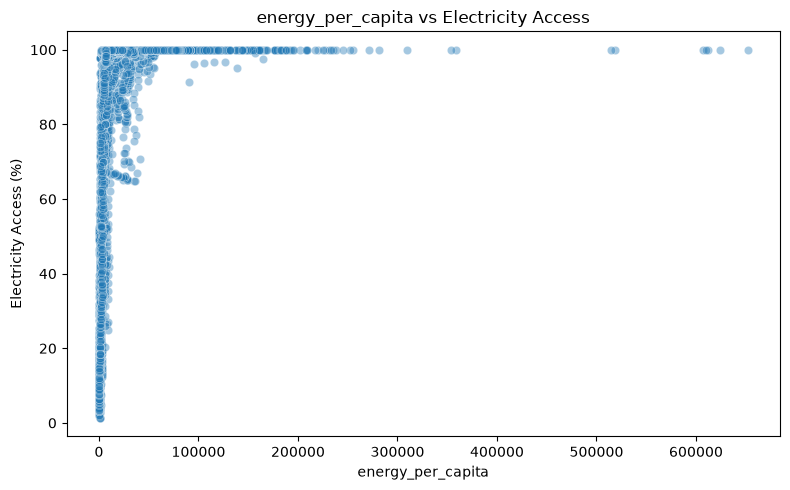

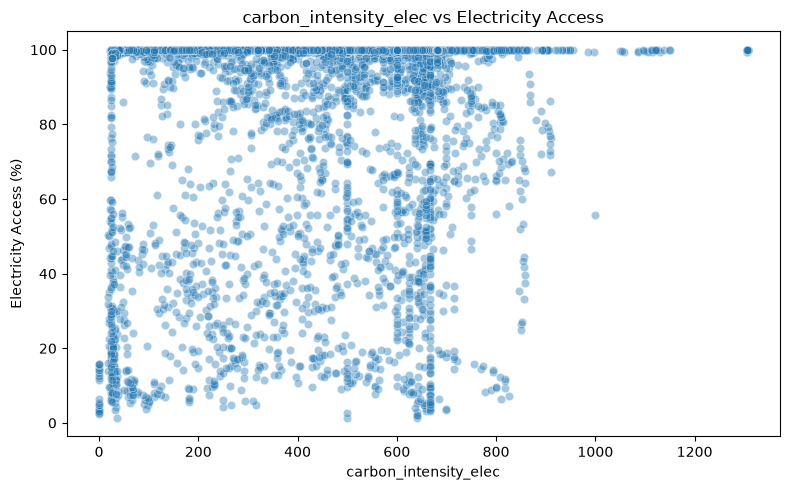

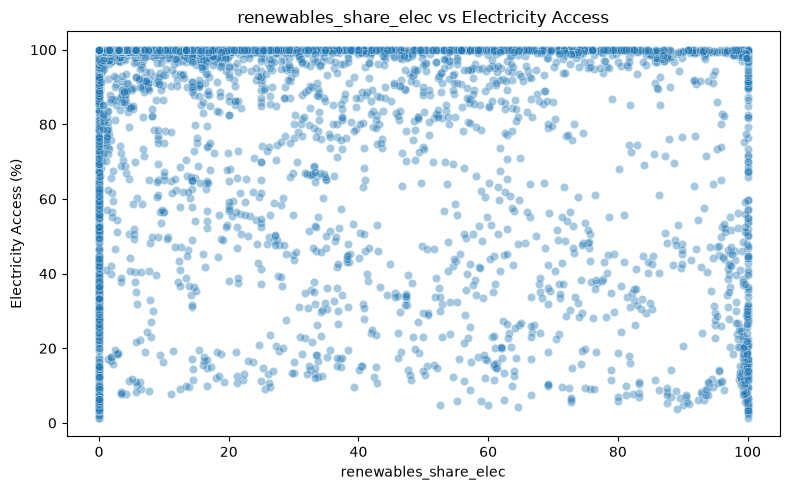

In [128]:
#SCATTER_PLOTS

# Scatter plots help us examine whether the relationship between a predictor and electricity access appears approximately linear.
# This matters because ordinary linear regression assumes that the conditional mean of the target can be represented adequately by a linear combination of the predictors.


# Define the target variable
target = "access_electricity_pct"

# Candidate predictors to investigate
candidate_predictors = [
    "gdp_per_capita_usd",
    "urban_pop_pct",
    "energy_per_capita",
    "carbon_intensity_elec",
    "renewables_share_elec"
]

# Create one scatter plot for each candidate predictor
for column in candidate_predictors:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=column,
        y=target,
        alpha=0.4
    )

    plt.title(f"{column} vs Electricity Access")
    plt.xlabel(column)
    plt.ylabel("Electricity Access (%)")
    plt.tight_layout()
    plt.show()

#### **Examine correlations with the target variable**

- We previously calculated the full correlation matrix. Now let's isolate the correlations with electricity access.

In [129]:
#FEATURE_SELECTION #CORRELATION_ANALYSIS

# This gives us a ranked view of which numerical variables have the strongest positive or negative linear associations with electricity access.

# Calculate correlations with the target variable
target_correlations = (
    df.select_dtypes(include=np.number)
      .corr()["access_electricity_pct"]
      .drop("access_electricity_pct")
      .sort_values(ascending=False)
)

print("Correlation of numerical variables with electricity access:")
display(target_correlations.to_frame(name="correlation"))

Correlation of numerical variables with electricity access:


,correlation
gdp_per_capita_log,0.732351
urban_pop_pct,0.630165
per_capita_electricity,0.420260
gdp_per_capita_usd,0.416966
energy_per_capita,0.378518
carbon_intensity_elec,0.194141
wind_share_elec,0.188288
fossil_share_elec,0.169835
year,0.151439
solar_share_elec,0.100327


#### **Select the target and predictors**
- Our target is access electricity pct. We'll use economic, demographic, and energy indicators as potential predictors.
- We'll exclude electricity gap pct because its perfect negative correlation indicates that it is mathematically dependent on the target
- We'll also exclude country and iso_code from this initial model because they are identifiers, not direct numerical measurements.

In [130]:
 #PHASE_4 #FEATURE_SELECTION

# In supervised machine learning:
# X contains the information used to make predictions.
# y contains the actual values the model must learn to predict. 

# Define the target variable we want to predict
target = "access_electricity_pct"

# Select candidate predictors
features = [
    "gdp_per_capita_log",
    "urban_pop_pct",
    "energy_per_capita",
    "carbon_intensity_elec",
    "fossil_share_elec",
    "hydro_share_elec",
    "solar_share_elec",
    "wind_share_elec",
    "population"
]

# Create the predictor matrix (X) and target vector (y)
X = df[features].copy()
y = df[target].copy()

# Confirm the dimensions
print("Predictor matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nSelected predictors:")
print(features)




Predictor matrix shape: (4338, 9)
Target vector shape: (4338,)

Selected predictors:
['gdp_per_capita_log', 'urban_pop_pct', 'energy_per_capita', 'carbon_intensity_elec', 'fossil_share_elec', 'hydro_share_elec', 'solar_share_elec', 'wind_share_elec', 'population']


#### **Note:**

- This variable has the strongest correlation with electricity access (−0.78), but it is negative.
- A likely reason is that the World Bank measure includes traditional biomass such as firewood and charcoal,
so countries where most people still cook with biomass score "high" on renewables while having low electricity access.
It therefore captures cooking-fuel dependence more than electricity supply.
- I left it out of the baseline model so the model reflects electricity-related indicators.
- In a quick check, adding it raised R² from about 0.60 to about 0.74, so it is a good candidate for a future version.

#### **Prepare the data for training**
- Before fitting a model, we need to ensure that all selected variables contain usable values. 

In [131]:
 #PHASE_4 #DATA_PREPARATION

# Combine predictors and target for consistent row filtering
model_data = pd.concat([X, y.rename(target)], axis=1)

# Replace infinite values with missing values
model_data = model_data.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing values in the selected variables
model_data = model_data.dropna()

# Separate the predictors and target again
X = model_data[features]
y = model_data[target]

# Display the resulting dataset dimensions
print("Rows available for modeling:", len(model_data))
print("Number of predictors:", X.shape[1])
print("Missing values remaining:", model_data.isnull().sum().sum())

# Check the target variable's range
print("\nTarget variable range:")
print("Minimum:", y.min())
print("Maximum:", y.max())


# Regression models cannot directly use missing or infinite values.
# This step ensures that our predictors and target contain valid numerical observations.
# We also check that the target falls within the expected range for a percentage. If the values are outside 0–100, we would need to investigate them before proceeding.

Rows available for modeling: 4338
Number of predictors: 9
Missing values remaining: 0

Target variable range:
Minimum: 1.3
Maximum: 100.0


#### **Split the data into training and testing sets**
- We will reserve 20% of the observations for testing and use the remaining 80% for training.

In [132]:
#TRAIN_TEST_SPLIT

from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# The training set is used to estimate the model's parameters
# The testing set is used to evaluate how well the model generalizes to unseen data.

Training observations: 3470
Testing observations: 868


### **Train the linear regression model**
- Now we'll train the model required by your assignment

In [133]:
#PHASE_4 #LINEAR_REGRESSION

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# WHY predictors differ in scale by about 8 orders of magnitude (population vs log GDP).
# Standardising first gives the same model mathematically but a numerically reliable fit.
linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)
print("Linear regression model trained successfully.")

Linear regression model trained successfully.


#### **Evaluate the baseline model**
- we require R2 and mean squared error (MSE)

In [134]:
 #PHASE_5 #MODEL_EVALUATION

from sklearn.metrics import r2_score, mean_squared_error

# Calculate evaluation metrics
r2_linear = r2_score(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)

print("LINEAR REGRESSION PERFORMANCE")
print("-----------------------------")
print(f"R-squared (R²): {r2_linear:.4f}")
print(f"Mean Squared Error (MSE): {mse_linear:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_linear:.4f}")

# R² measures how much of the variation in the test-set target is explained by the model relative to predicting the test-set mean.
# MSE is the average squared difference between actual and predicted values.
# RMSE is the square root of MSE, providing an error metric in the same units as the target variable (percentage points of electricity access).

LINEAR REGRESSION PERFORMANCE
-----------------------------
R-squared (R²): 0.5969
Mean Squared Error (MSE): 362.8982
Root Mean Squared Error (RMSE): 19.0499


#### TESTING LINEAR REGRESSION ASSUMPTIONS

- We'll examine the following:

Linearity.
Multicollinearity.
Homoscedasticity.
Residual normality.
Independence of errors.

No single diagnostic proves that a model is appropriate. We'll interpret the tests together with the plots and the structure of the data.

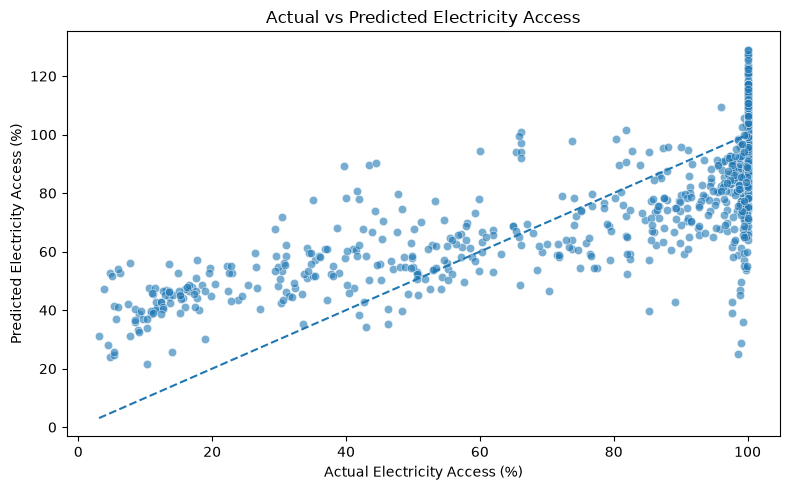

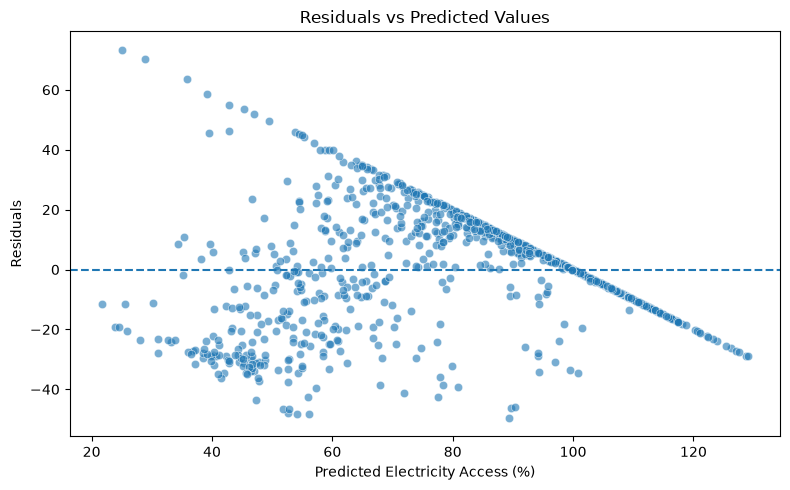

In [135]:
# We'll examine the following:

 #PHASE_5 #LINEARITY #RESIDUAL_DIAGNOSTICS

# Calculate residuals on the test set
residuals = y_test - y_pred_linear

# Plot actual versus predicted values
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_test, y=y_pred_linear, alpha=0.6)

# Reference line representing perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Electricity Access (%)")
plt.ylabel("Predicted Electricity Access (%)")
plt.title("Actual vs Predicted Electricity Access")
plt.tight_layout()
plt.show()

# Plot residuals against predicted values
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred_linear, y=residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Electricity Access (%)")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.tight_layout()
plt.show()

# Points close to the diagonal indicate accurate predictions
# Ideally, residuals should be scattered around zero without a clear curve or systematic pattern.
# A curved pattern may indicate that the model does not adequately capture the relationship between predictors and electricity access.

#### Test multicollinearity using VIF
- Multicollinearity occurs when two or more predictors are strongly related to one another
- It can make individual regression coefficients unstable and difficult to interpret.


In [136]:
 #PHASE_5 #MULTICOLLINEARITY #VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF using the training predictors
X_vif = sm.add_constant(X_train)

vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# The intercept is not a predictor, so exclude it from the displayed table
vif_results = vif_results[
    vif_results["Feature"] != "const"
].sort_values("VIF", ascending=False)

display(vif_results)

# Vif near or above 10 suggests that a predictor is highly collinear with others, which can inflate the variance of coefficient estimates and make the model unstable.
# VIF is calculated using the training set to avoid data leakage.


,Feature,VIF
5,fossil_share_elec,12.007161
4,carbon_intensity_elec,7.344281
6,hydro_share_elec,6.851175
1,gdp_per_capita_log,2.858894
2,urban_pop_pct,2.130434
3,energy_per_capita,1.598760
8,wind_share_elec,1.382280
7,solar_share_elec,1.129893
9,population,1.042991


#### **Test homoscedasticity**
- Homoscedasticity means that the error variance is approximately constant across the range of fitted values

In [137]:
#PHASE_5 #HOMOSCEDASTICITY

from statsmodels.stats.diagnostic import het_breuschpagan

# Add a constant to the training predictors
X_train_sm = sm.add_constant(X_train)

# Fit an OLS model for statistical diagnostics
ols_model = sm.OLS(y_train, X_train_sm).fit()

# Calculate the Breusch-Pagan test
bp_test = het_breuschpagan(
    ols_model.resid,
    ols_model.model.exog
)

bp_labels = [
    "LM Statistic",
    "LM-Test p-value",
    "F Statistic",
    "F-Test p-value"
]

bp_results = dict(zip(bp_labels, bp_test))

print("BREUSCH-PAGAN TEST")
for label, value in bp_results.items():
    print(f"{label}: {value:.6f}")

if bp_results["LM-Test p-value"] < 0.05:
    print("\nEvidence of non-constant residual variance at the 5% significance level.")
else:
    print("\nInsufficient evidence of non-constant residual variance at the 5% significance level.")

    # If the test indicates heteroscedasticity, we can consider heteroscedasticity-robust standard errors for statistical inference. Ridge regression alone does not solve heteroscedasticity.

BREUSCH-PAGAN TEST
LM Statistic: 724.261222
LM-Test p-value: 0.000000
F Statistic: 101.407390
F-Test p-value: 0.000000

Evidence of non-constant residual variance at the 5% significance level.


#### Test residual normality
- Residual normality is relevant to conventional small-sample statistical inference. It is not a requirement for calculating predictions or for OLS coefficients to be estimated.

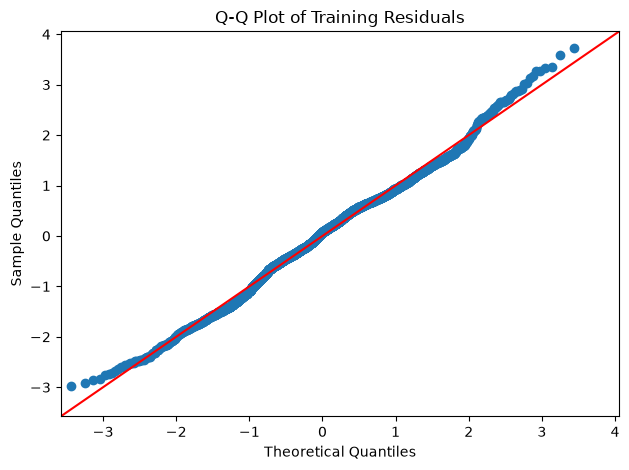

JARQUE-BERA NORMALITY TEST
Test statistic: 2.0781
p-value: 0.353782
Insufficient evidence to reject residual normality at the 5% significance level.


In [138]:
#PHASE_5 #RESIDUAL_NORMALITY

from scipy.stats import jarque_bera
import statsmodels.api as sm

# Calculate residuals from the training OLS model
training_residuals = ols_model.resid

# Plot a Q-Q plot
sm.qqplot(training_residuals, line="45", fit=True)

plt.title("Q-Q Plot of Training Residuals")
plt.tight_layout()
plt.show()

# Perform the Jarque-Bera test
jb_statistic, jb_pvalue = jarque_bera(training_residuals)

print("JARQUE-BERA NORMALITY TEST")
print(f"Test statistic: {jb_statistic:.4f}")
print(f"p-value: {jb_pvalue:.6f}")

if jb_pvalue < 0.05:
    print("Evidence against normally distributed residuals at the 5% significance level.")
else:
    print("Insufficient evidence to reject residual normality at the 5% significance level.")

    # The Jarque–Bera test examines whether the residual distribution's skewness and kurtosis are consistent with normality

#### Investigate independence of errors
- Your dataset contains repeated observations for countries across different years. Therefore, observations from the same country may not be independent
- We can calculate the Durbin–Watson statistic as an initial residual diagnostic.

In [139]:
#PHASE_5 #RESIDUAL_INDEPENDENCE
from statsmodels.stats.stattools import durbin_watson

# #WHY the training rows were shuffled by train_test_split, and Durbin-Watson only
#      makes sense when rows are in time order, so sort residuals back by country and year first
dw_statistic = durbin_watson(ols_model.resid.sort_index())
print(f"Durbin-Watson statistic (country-year order): {dw_statistic:.3f}")
# 2 is ideal; values near 0 mean strong positive dependence between consecutive years

Durbin-Watson statistic (country-year order): 0.147


#### Assumption test summary
| Assumption | Test | Result | Conclusion |
|---|---|---|---|
| Linearity | Actual vs predicted, residuals vs predicted | <describe what you see in the plots> | <linear enough / curved> |
| Multicollinearity | VIF | fossil_share_elec = 12.0, carbon_intensity_elec = 7.3, hydro_share_elec = 6.9 | Fossil share exceeds 10, so predictors overlap |
| Constant variance | Breusch-Pagan | p < 0.001 | Violated: errors are not equally spread |
| Normal residuals | Jarque-Bera | p = 0.354 | No evidence against normality |
| Independence | Durbin-Watson (sorted) | about 0.15 | Violated: the same country appears in many years |

**What this means:** the model is useful for describing broad patterns, but standard errors and significance
tests should not be trusted, because variance is uneven and years within a country are related.
Ridge addresses the overlap between predictors but not the variance or dependence problems.

#### RIDGE REGRESSION AND MODEL COMPARISON
**Train a Ridge regression model**
- Ridge regression adds an L2 penalty to the regression objective. This penalizes large coefficients and can help stabilize estimates when predictors are highly correlated.

In [140]:
#PHASE_4 #RIDGE_REGRESSION #REGULARIZATION

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

# #WHY Ridge needs predictors on the same scale, hence StandardScaler
# #WHY RidgeCV tries 25 alpha values on the training data only and keeps the best,
#      instead of us guessing alpha = 1.0
ridge_model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-3, 3, 25), cv=5)
)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

print("Ridge regression trained. Best alpha:", ridge_model[-1].alpha_)
# Ordinary linear regression minimizes the sum of squared residuals.
# Ridge regression adds a penalty proportional to the squared magnitude of the coefficients.
# This can improve coefficient stability when multicollinearity is present

Ridge regression trained. Best alpha: 10.0


#### **COMPARE THE MODELS**

In [141]:
#PHASE_5 #MODEL_COMPARISON

# Evaluate ordinary linear regression
linear_r2 = r2_score(y_test, y_pred_linear)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(linear_mse)

# Evaluate Ridge regression
ridge_r2 = r2_score(y_test, y_pred_ridge)
ridge_mse = mean_squared_error(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(ridge_mse)

# Create a comparison table
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "R2": [linear_r2, ridge_r2],
    "MSE": [linear_mse, ridge_mse],
    "RMSE": [linear_rmse, ridge_rmse]
})

display(model_comparison.round(4))

# The comparison table allows us to assess which model better explains the variation in electricity access and has lower prediction errors on the test set.

,Model,R2,MSE,RMSE
0,Linear Regression,0.5969,362.8982,19.0499
1,Ridge Regression,0.5968,362.9223,19.0505


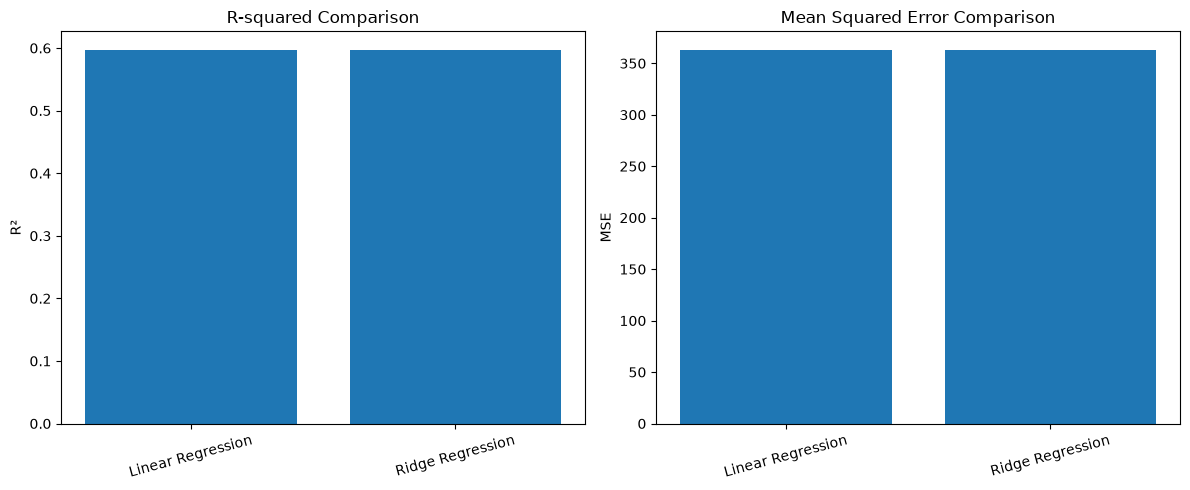

In [142]:
# PLOT THE MODEL COMPARIZON

#PHASE_5 #MODEL_VISUALIZATION

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare R-squared values
axes[0].bar(
    model_comparison["Model"],
    model_comparison["R2"]
)

axes[0].set_title("R-squared Comparison")
axes[0].set_ylabel("R²")
axes[0].tick_params(axis="x", rotation=15)

# Compare mean squared errors
axes[1].bar(
    model_comparison["Model"],
    model_comparison["MSE"]
)

axes[1].set_title("Mean Squared Error Comparison")
axes[1].set_ylabel("MSE")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

# This visualization provides a clear side-by-side comparison of the two models' performance metrics, helping us determine which model is more effective for predicting electricity access.

#### INTERPRETATION AND FINAL RESULTS
**Inspect the linear regression coefficients**
- We'll inspect the coefficients from the ordinary linear regression model.

In [143]:
scaler = linear_model[0]
lr = linear_model[-1]

coefficients = pd.DataFrame({
    "Feature": features,
    "Standardized coefficient": lr.coef_,
    "Per original unit": lr.coef_ / scaler.scale_,
}).sort_values("Standardized coefficient", ascending=False)

display(coefficients.round(6))
print("Intercept (standardized model):", round(lr.intercept_, 4))

# Standardized: change in access (percentage points) per 1 standard deviation of the predictor.
# Per original unit: change per 1 unit of the predictor as measured (for example 1 person for population)

,Feature,Standardized coefficient,Per original unit
0,gdp_per_capita_log,18.735805,12.039304
3,carbon_intensity_elec,8.067818,0.032487
1,urban_pop_pct,6.723971,0.287998
8,population,2.225862,0.000000
6,solar_share_elec,0.279363,0.107822
5,hydro_share_elec,-0.925642,-0.029050
7,wind_share_elec,-1.309310,-0.264067
2,energy_per_capita,-3.160640,-0.000079
4,fossil_share_elec,-6.445390,-0.189154


Intercept (standardized model): 80.0907


### **Deployment**
save the trained model
- A saved model allows you to reuse the fitted estimator without training it again.

In [151]:
 #FIX #FINAL_MODEL_PREDICTIONS

# Select the model with the higher R-squared score
if ridge_r2 > linear_r2:
    final_model = ridge_model
    final_predictions = ridge_model.predict(X_test)
    final_model_name = "Ridge Regression"
else:
    final_model = linear_model
    final_predictions = linear_model.predict(X_test)
    final_model_name = "Linear Regression"

# Confirm the predictions have been created
print("Selected model:", final_model_name)
print("Number of predictions:", len(final_predictions))
print("Number of actual observations:", len(y_test))



Selected model: Linear Regression
Number of predictions: 868
Number of actual observations: 868


In [152]:
#PHASE_5 #PREDICTION_BOUNDS
#WHY access cannot exceed 100% or fall below 0%, so we cap the predictions
print("Predictions above 100%:", (final_predictions > 100).sum(), "of", len(final_predictions))

final_predictions_clipped = np.clip(final_predictions, 0, 100)
print(f"R² (clipped):   {r2_score(y_test, final_predictions_clipped):.4f}")
print(f"MSE (clipped):  {mean_squared_error(y_test, final_predictions_clipped):.2f}")
print(f"RMSE (clipped): {np.sqrt(mean_squared_error(y_test, final_predictions_clipped)):.2f}")

Predictions above 100%: 185 of 868
R² (clipped):   0.6264
MSE (clipped):  336.31
RMSE (clipped): 18.34


In [153]:
#PHASE_6 #MODEL_DEPLOYMENT

import joblib
from pathlib import Path

# Create a directory for saved models
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the selected model
model_path = model_dir / "sdg7_electricity_access_model.pkl"

joblib.dump(final_model, model_path)

print("Final model saved to:", model_path)

Final model saved to: models\sdg7_electricity_access_model.pkl


In [154]:
#PHASE_6 #MODEL_DEPLOYMENT #DEMO
#  #WHY a saved model is only useful if it can be loaded and used again without retraining
loaded_model = joblib.load(model_path)

# 1. Predictions from the loaded model on five unseen test rows
sample = X_test.sample(5, random_state=1)
demo = pd.DataFrame({
    "country": df.loc[sample.index, "country"],
    "year": df.loc[sample.index, "year"],
    "actual_access_%": y_test.loc[sample.index].round(1),
    "predicted_access_%": np.clip(loaded_model.predict(sample), 0, 100).round(1),
})
display(demo)

# 2. A what-if tool: change one input, hold the rest at typical (median) values
def predict_access(**changes):
    row = X_train.median().to_dict()
    row.update(changes)
    pred = loaded_model.predict(pd.DataFrame([row])[features])[0]
    return round(float(np.clip(pred, 0, 100)), 1)

for gdp in (500, 2000, 10000, 40000):
    print(f"GDP per capita ${gdp:>6,}: predicted access = {predict_access(gdp_per_capita_log=np.log(gdp))}%")

,country,year,actual_access_%,predicted_access_%
4701,Ukraine,2006,99.5,75.9
1556,France,2015,100.0,100.0
2080,Haiti,2010,37.2,60.8
1549,France,2008,100.0,100.0
1268,Dominican Republic,2003,89.2,74.8


GDP per capita $   500: predicted access = 54.2%
GDP per capita $ 2,000: predicted access = 70.9%
GDP per capita $10,000: predicted access = 90.3%
GDP per capita $40,000: predicted access = 100.0%


#### Deployment summary
- The final model (a Ridge pipeline: scaler + regression) is saved with `joblib` to `models/sdg7_electricity_access_model.pkl`.
  joblib files are pickle-format files, so the model can be reloaded in any Python environment with the same library versions.
- Because the scaler is inside the pipeline, new data goes in raw, with no manual preprocessing.
- Predictions are capped to 0–100%, since access cannot leave that range.
- Delivery: the dashboard design for non-technical readers, and this documented GitHub repository for anyone who wants to rerun or reuse the work.

#### FINAL PROJECT CONCLUSION
**Generate a results summary**

In [155]:
#PHASE_5 #FINAL_RESULTS_SUMMARY

final_r2 = r2_score(y_test, final_predictions)
final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)

print("SDG 7 ELECTRICITY ACCESS ANALYSIS")
print("=" * 40)

print(f"Observations used: {len(model_data)}")
print(f"Training observations: {len(X_train)}")
print(f"Testing observations: {len(X_test)}")
print(f"Number of predictors: {len(features)}")

print("\nSelected Model:", final_model_name)

print(f"R-squared: {final_r2:.4f}")
print(f"Mean Squared Error: {final_mse:.4f}")
print(f"Root Mean Squared Error: {final_rmse:.4f}")

print("\nPredictors:")
for feature in features:
    print("-", feature)

SDG 7 ELECTRICITY ACCESS ANALYSIS
Observations used: 4338
Training observations: 3470
Testing observations: 868
Number of predictors: 9

Selected Model: Linear Regression
R-squared: 0.5969
Mean Squared Error: 362.8982
Root Mean Squared Error: 19.0499

Predictors:
- gdp_per_capita_log
- urban_pop_pct
- energy_per_capita
- carbon_intensity_elec
- fossil_share_elec
- hydro_share_elec
- solar_share_elec
- wind_share_elec
- population


In [156]:
# FINAL MODEL EVALUATION SUMMARY

evaluation_results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "R2": [linear_r2, ridge_r2],
    "MSE": [linear_mse, ridge_mse],
    "RMSE": [linear_rmse, ridge_rmse]
})

display(evaluation_results.round(4)) 

,Model,R2,MSE,RMSE
0,Linear Regression,0.5969,362.8982,19.0499
1,Ridge Regression,0.5968,362.9223,19.0505


### Future work
**Next steps**
- Build the live dashboard (Power BI or Streamlit) from the cleaned dataset.
- Bound the model's output to 0–100% by design, for example by modelling the log-odds of access.
- Test the biomass-adjusted renewable measure (`renewable_final_energy_pct` raised R² from about 0.60 to 0.74 in a quick check).

**Beyond this project**
- Use panel-data methods (country effects) to handle repeated years within a country.
- Add affordability and reliability indicators (SDG 7 is about all three, not just access).
- Predict sub-national or household-level access with survey or satellite data.

### What is new beyond class
- Built the dataset from two real, non-Kaggle sources through the World Bank API, with retries and file caching.
- Checked for target leakage (the access gap is exactly 100 minus the target) and excluded it.
- Filled missing values within each country over time, not with one global average.
- Tested all regression assumptions and found that independence fails, which only shows up when residuals are sorted by country and year.
- Chose the Ridge strength by cross-validation and standardised features inside a pipeline.
- Found that an unscaled linear fit was numerically unreliable on this data and fixed it by scaling.
- Capped predictions to the valid 0–100% range, which improved the fit.
- Delivered a reusable saved model and a documented, reproducible GitHub repository.